# [Dawlaty Lab's TET knockout dataset](https://www.dawlatylaboratory.com/)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2024-12-08
> - Modified: 2025-05-04

# 1. Experimental Design

> 1. Dawlaty Lab's Tet1, [GSE176389](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE176389)
> 2. Dawlaty Lab's Tet2, [GSE213398](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE213398)
> 3. Dawlaty Lab's Tet3, [GSE237800](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE237800)
> 4. Dawlaty Lab's Tet1/2/3 TKO, [GSE248933](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE248933)
> 5. Bulut-Karslioglu Lab's Tet1/2 DKO, [GSE221470](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE221470) (*Warning:* Methylation levels in Tet1/2 dKO samples are abnormally lower than in the control group.)

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir1 <- "~/dataset_1/bulk_omics/multiomics_Mm_mESC_Tet1_GSE176389/00_geo"
data_dir2 <- "~/dataset_1/bulk_omics/multiomics_Mm_mESC_Tet2_GSE213398/00_geo"
data_dir3 <- "~/dataset_1/bulk_omics/multiomics_Mm_mNEC_Tet3_GSE237800/00_geo"
data_dir4 <- "~/dataset_1/bulk_omics/multiomics_Mm_mESC_Tets_GSE221470/00_geo"
data_dir5 <- "~/dataset_1/bulk_omics/multiomics_Mm_mESC_Tets_GSE248933/00_geo"

outdir <- "~/dataset_1/bulk_omics/multiomics_Mm_mESC_Tets_DawlatyLab"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"

In [3]:
suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

suppressPackageStartupMessages(library(TxDb.Mmusculus.UCSC.mm10.knownGene))
txdb <- TxDb.Mmusculus.UCSC.mm10.knownGene

# 2. Import Data

## 1). Import bigwig

In [4]:
# Load bigwig (bw) file as GRanges
load_bigwig <- function(
    file, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE, 
    blacklist = NULL, scaleFactor = NULL) {

    gr <- rtracklayer::import.bw(file)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist regions (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    if (!is.null(scaleFactor) && "score" %in% names(GenomicRanges::mcols(gr))) {
        gr$score <- gr$score * scaleFactor
    }

    return(gr)
}

In [5]:
signals_files1 <- list.files(
    data_dir1, pattern = ".*mCG.*\\.bw$", full.names = TRUE) |>
    set_names(c(
        "mESC_TET1_WT_rep1", "mESC_TET1_WT_rep2", 
        "mESC_TET1_Mut_rep1", "mESC_TET1_Mut_rep2", 
        "mESC_TET1_KO_rep1", "mESC_TET1_KO_rep2"))
signals_files2 <- list.files(
    data_dir2, pattern = ".*Tet2.*WGBS.bw$", full.names = TRUE) |>
    set_names(c(
        "mESC_TET2_KO_repN", "mESC_TET2_Mut_repN", "mESC_TET2_WT_repN"))
signals_files3 <- list.files(
    data_dir3, pattern = ".*Tet3.*WGBS.bw$", full.names = TRUE) |>
    set_names(c(
        "mNEC_TET3_KO_repN", "mNEC_TET3_Mut_repN", "mNEC_TET3_WT_repN"))
signals_files4 <- list.files(
    data_dir4, pattern = ".*WBGS.*N.*.bw$", full.names = TRUE) |>
    set_names(c(
        "mESC_TET12_WT_rep1", "mESC_TET12_WT_rep2", 
        "mESC_TET12_DKO_rep1", "mESC_TET12_DKO_rep2"))
signals_files5 <- list.files(
    data_dir5, pattern = ".*Tet.*WGBS.bw$", full.names = TRUE) |>
    set_names(c(
        "mESC_TETs_WT_repN", "mESC_TETs_TKO_repN", 
        "mNSC_TETs_WT_repN", "mNSC_TETs_TKO_repN"))

In [6]:
signals_list1 <- lapply(
    signals_files1, load_bigwig, dropSex = FALSE, scaleFactor = 100)
signals_list2 <- lapply(
    signals_files2, load_bigwig, dropSex = FALSE)
signals_list3 <- lapply(
    signals_files3, load_bigwig, dropSex = FALSE)
signals_list4 <- lapply(
    c(signals_files4), load_bigwig, dropSex = FALSE, scaleFactor = 100)
signals_list5 <- lapply(
    signals_files5, load_bigwig, dropSex = FALSE)

In [7]:
signals_list1[1]
signals_list4[1]

$mESC_TET1_WT_rep1
GRanges object with 40137399 ranges and 1 metadata column:
             seqnames    ranges strand |     score
                <Rle> <IRanges>  <Rle> | <numeric>
         [1]     chr1   3000827      * |  100.0000
         [2]     chr1   3000828      * |  100.0000
         [3]     chr1   3001007      * |   87.5000
         [4]     chr1   3001008      * |  100.0000
         [5]     chr1   3001018      * |   86.9565
         ...      ...       ...    ... .       ...
  [40137395]     chrY  90831867      * |  100.0000
  [40137396]     chrY  90832200      * |   66.6667
  [40137397]     chrY  90832204      * |   66.6667
  [40137398]     chrY  90832213      * |   33.3333
  [40137399]     chrY  90832217      * |   50.0000
  -------
  seqinfo: 21 sequences from an unspecified genome


$mESC_TET12_WT_rep1
GRanges object with 18959115 ranges and 1 metadata column:
             seqnames              ranges strand |     score
                <Rle>           <IRanges>  <Rle> | <numeric>
         [1]     chr1     3000827-3000828      * |      75.0
         [2]     chr1     3001007-3001008      * |      57.1
         [3]     chr1     3001018-3001019      * |      46.7
         [4]     chr1     3001277-3001278      * |      28.6
         [5]     chr1     3001629-3001630      * |      26.1
         ...      ...                 ...    ... .       ...
  [18959111]     chr9 124490108-124490109      * |      17.6
  [18959112]     chr9 124490122-124490123      * |      40.0
  [18959113]     chr9 124490296-124490297      * |      50.0
  [18959114]     chr9 124490496-124490497      * |      11.8
  [18959115]     chr9 124491756-124491757      * |      81.2
  -------
  seqinfo: 19 sequences from an unspecified genome


## 2). CpG Aggregation

> Strand-aware CpG methylation aggregation
> - CpG methylation calls from the Watson and Crick strands were combined to produce unified CpG-level profiles. For each CpG site, strand-specific methylated (C) and unmethylated (T) read counts were summed, and methylation levels were recalculated as the ratio of total methylated reads to total coverage across both strands. This aggregation strategy provides a single, strand-independent representation of CpG methylation for downstream analysis.

In [8]:
# Extracting CpG sites from genome
CpGs <- lapply(seqnames(genome), function(chr) {
    seq <- getSeq(genome, chr)
    pos <- Biostrings::matchPattern("CG", seq)
    GRanges(chr, IRanges(start = start(pos), end = end(pos)), strand = "+")
}) |>
    GRangesList() |> unlist() |>
    GenomeInfoDb::keepStandardChromosomes(pruning.mode = "coarse") |>
    GenomeInfoDb::dropSeqlevels("chrM", pruning.mode = "coarse")

CpGs

GRanges object with 21867550 ranges and 0 metadata columns:
             seqnames            ranges strand
                <Rle>         <IRanges>  <Rle>
         [1]     chr1   3000827-3000828      +
         [2]     chr1   3001007-3001008      +
         [3]     chr1   3001018-3001019      +
         [4]     chr1   3001277-3001278      +
         [5]     chr1   3001629-3001630      +
         ...      ...               ...    ...
  [21867546]     chrY 90844625-90844626      +
  [21867547]     chrY 90844627-90844628      +
  [21867548]     chrY 90844638-90844639      +
  [21867549]     chrY 90844649-90844650      +
  [21867550]     chrY 90844676-90844677      +
  -------
  seqinfo: 21 sequences from an unspecified genome; no seqlengths

In [9]:
aggregate_cpg_methylation <- function(input, cpg) {
    message("Aggregating methylation to CpG sites...")

    hits <- GenomicRanges::findOverlaps(cpg, input, ignore.strand = TRUE)

    if (length(hits) == 0) return(NULL)

    df <- data.table::data.table(
        cpg_idx = queryHits(hits),
        score = input$score[subjectHits(hits)]
    )

    agg <- df[, .(score = mean(score, na.rm = TRUE)), by = cpg_idx]

    if (nrow(agg) == 0) return(NULL)

    result <- cpg[agg$cpg_idx]
    result$score <- agg$score

    return(result)
}

In [10]:
signals_list1 <- lapply(signals_list1, aggregate_cpg_methylation, cpg = CpGs)

signals_list1[1]

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...



$mESC_TET1_WT_rep1
GRanges object with 20601028 ranges and 1 metadata column:
             seqnames            ranges strand |     score
                <Rle>         <IRanges>  <Rle> | <numeric>
         [1]     chr1   3000827-3000828      + |  100.0000
         [2]     chr1   3001007-3001008      + |   93.7500
         [3]     chr1   3001018-3001019      + |   93.4783
         [4]     chr1   3001277-3001278      + |   95.0000
         [5]     chr1   3001629-3001630      + |   93.3333
         ...      ...               ...    ... .       ...
  [20601024]     chrY 90831867-90831868      + |  100.0000
  [20601025]     chrY 90832200-90832201      + |   66.6667
  [20601026]     chrY 90832204-90832205      + |   66.6667
  [20601027]     chrY 90832213-90832214      + |   33.3333
  [20601028]     chrY 90832217-90832218      + |   50.0000
  -------
  seqinfo: 21 sequences from an unspecified genome; no seqlengths


In [11]:
signals_list2 <- lapply(signals_list2, aggregate_cpg_methylation, cpg = CpGs)
signals_list3 <- lapply(signals_list3, aggregate_cpg_methylation, cpg = CpGs)
signals_list5 <- lapply(signals_list5, aggregate_cpg_methylation, cpg = CpGs)

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...



In [12]:
signals_list <- c(
    signals_list1, signals_list2, signals_list3, 
    signals_list4, signals_list5)

In [13]:
coldata <- data.frame(sample = names(signals_list)) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Cell = factor(
            Cell, levels = c("mESC", "mNEC", "mNSC")),
        Gene = factor(
            Gene, levels = c("TET1", "TET2", "TET3", "TET12", "TETs")),
        Genotype = factor(
            Genotype, levels = c("WT", "Mut", "KO", "DKO", "TKO")),
        Group = forcats::fct_cross(Gene, Genotype, sep = "_"),
        Replicate = factor(
            Replicate, levels = c("repN", "rep1", "rep2"))) |>
    arrange(Gene, Cell, Genotype, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Genotype,Replicate,Group
,<fct>,<fct>,<fct>,<fct>,<fct>
mESC_TET1_WT_rep1,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep2,mESC,TET1,WT,rep2,TET1_WT
mESC_TET1_Mut_rep1,mESC,TET1,Mut,rep1,TET1_Mut
mESC_TET1_Mut_rep2,mESC,TET1,Mut,rep2,TET1_Mut
mESC_TET1_KO_rep1,mESC,TET1,KO,rep1,TET1_KO
mESC_TET1_KO_rep2,mESC,TET1,KO,rep2,TET1_KO
mESC_TET2_WT_repN,mESC,TET2,WT,repN,TET2_WT
mESC_TET2_Mut_repN,mESC,TET2,Mut,repN,TET2_Mut
mESC_TET2_KO_repN,mESC,TET2,KO,repN,TET2_KO


In [14]:
sample_index <- rownames(coldata)
signals_list <- signals_list[sample_index]

In [15]:
# ~ 6 minutes
bw_dir <- file.path(outdir, "bigwig")
dir.create(bw_dir, recursive = TRUE, showWarnings = FALSE)

purrr::walk(names(signals_list), function(idx) {
    gr <- signals_list[[idx]]

    GenomeInfoDb::seqinfo(gr) <- GenomeInfoDb::seqinfo(genome)[
        GenomeInfoDb::seqlevels(gr)]

    gr <- BiocGenerics::sort(gr)

    out_file <- file.path(bw_dir, paste0(idx, ".bw"))
    rtracklayer::export.bw(gr, out_file)

    message("Successfully exported: ", idx)
})

Successfully exported: mESC_TET1_WT_rep1

Successfully exported: mESC_TET1_WT_rep2

Successfully exported: mESC_TET1_Mut_rep1

Successfully exported: mESC_TET1_Mut_rep2

Successfully exported: mESC_TET1_KO_rep1

Successfully exported: mESC_TET1_KO_rep2

Successfully exported: mESC_TET2_WT_repN

Successfully exported: mESC_TET2_Mut_repN

Successfully exported: mESC_TET2_KO_repN

Successfully exported: mNEC_TET3_WT_repN

Successfully exported: mNEC_TET3_Mut_repN

Successfully exported: mNEC_TET3_KO_repN

Successfully exported: mESC_TET12_WT_rep1

Successfully exported: mESC_TET12_WT_rep2

Successfully exported: mESC_TET12_DKO_rep1

Successfully exported: mESC_TET12_DKO_rep2

Successfully exported: mESC_TETs_WT_repN

Successfully exported: mESC_TETs_TKO_repN

Successfully exported: mNSC_TETs_WT_repN

Successfully exported: mNSC_TETs_TKO_repN



# 3. Evaluate Library Quality

In [16]:
plot_df <- data.frame(
    sample = names(signals_list),
    number = sapply(signals_list, length),
    mean = sapply(signals_list, \(gr) mean(mcols(gr)$score))) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = sample_index))

head(plot_df)

,sample,number,mean,Cell,Gene,Genotype,Replicate,Group
,<fct>,<int>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>
1,mESC_TET1_WT_rep1,20601028,69.35859,mESC,TET1,WT,rep1,TET1_WT
2,mESC_TET1_WT_rep2,20639651,68.09758,mESC,TET1,WT,rep2,TET1_WT
3,mESC_TET1_Mut_rep1,20627337,71.57211,mESC,TET1,Mut,rep1,TET1_Mut
4,mESC_TET1_Mut_rep2,20619540,71.78194,mESC,TET1,Mut,rep2,TET1_Mut
5,mESC_TET1_KO_rep1,20665594,74.64064,mESC,TET1,KO,rep1,TET1_KO
6,mESC_TET1_KO_rep2,20649906,67.05115,mESC,TET1,KO,rep2,TET1_KO


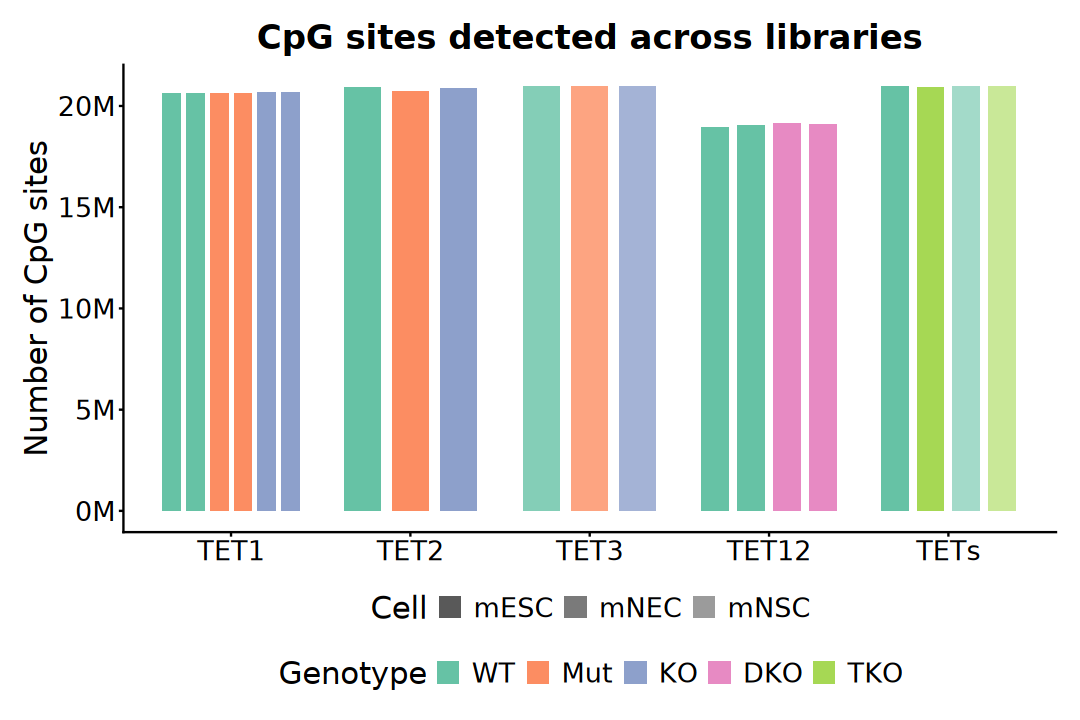

In [17]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Gene, y = number, group = sample)) +
    geom_bar(
        aes(fill = Genotype, alpha = Cell), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    scale_alpha_manual(values = c(1, 0.8, 0.6)) +
    guides(alpha = guide_legend(order = 1), fill = guide_legend(order = 2)) +
    labs(
        title = "CpG sites detected across libraries", 
        x = NULL, y = "Number of CpG sites") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        legend.box = "vertical", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

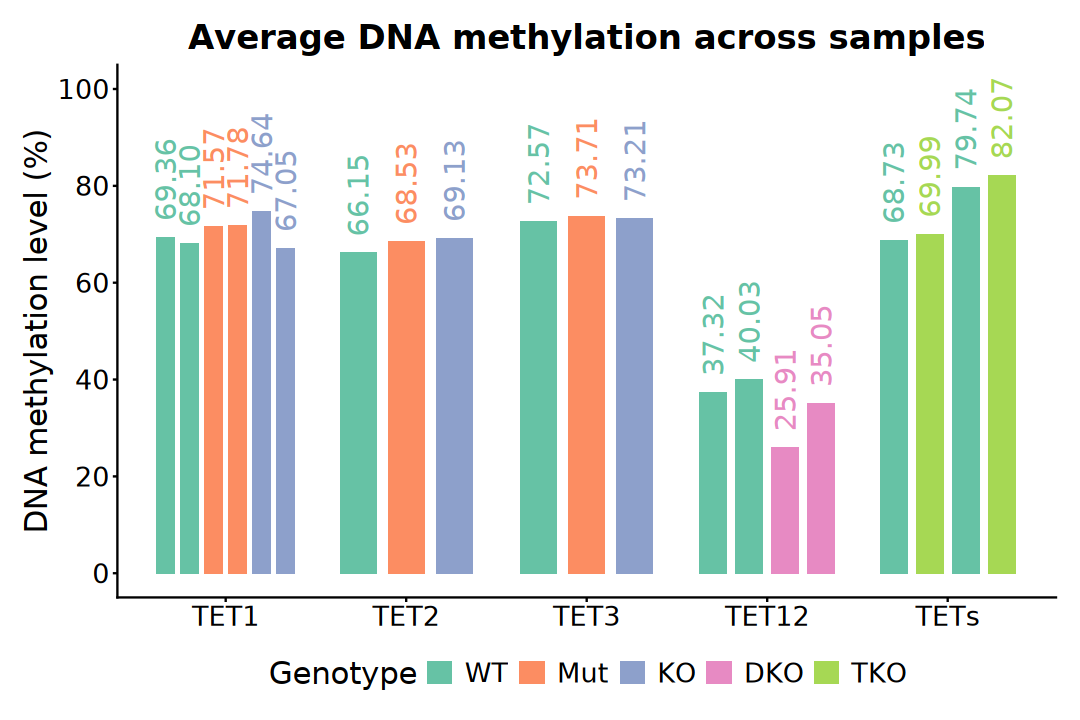

In [18]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Gene, y = mean, group = sample)) +
    geom_bar(
        aes(fill = Genotype), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    geom_text(
        aes(color = Genotype, label = sprintf("%.2f", round(mean, 2))),
        position = position_dodge(width = 0.8),
        angle = 90, vjust = 0.5, hjust = -0.2, size = 6) +
    scale_y_continuous(breaks = seq(0, 100, 20), limits = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Average DNA methylation across samples",
        x = NULL, y = "DNA methylation level (%)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [19]:
bins <- 0:100

plot_df <- map_df(names(signals_list), function(idx) {
    scores <- mcols(signals_list[[idx]])$score
    counts <- table(cut(scores, breaks = bins, include.lowest = TRUE))
    data.frame(
        sample = idx, bin_center = 0.5:99.5, count = as.numeric(counts), 
        prop = as.numeric(counts) / length(scores))
}) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = sample_index))

head(plot_df)

,sample,bin_center,count,prop,Cell,Gene,Genotype,Replicate,Group
,<fct>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>
1,mESC_TET1_WT_rep1,0.5,1425736,0.0692070318,mESC,TET1,WT,rep1,TET1_WT
2,mESC_TET1_WT_rep1,1.5,1752,0.0000850443,mESC,TET1,WT,rep1,TET1_WT
3,mESC_TET1_WT_rep1,2.5,21290,0.0010334436,mESC,TET1,WT,rep1,TET1_WT
4,mESC_TET1_WT_rep1,3.5,45342,0.0022009581,mESC,TET1,WT,rep1,TET1_WT
5,mESC_TET1_WT_rep1,4.5,41947,0.0020361605,mESC,TET1,WT,rep1,TET1_WT
6,mESC_TET1_WT_rep1,5.5,59729,0.0028993213,mESC,TET1,WT,rep1,TET1_WT


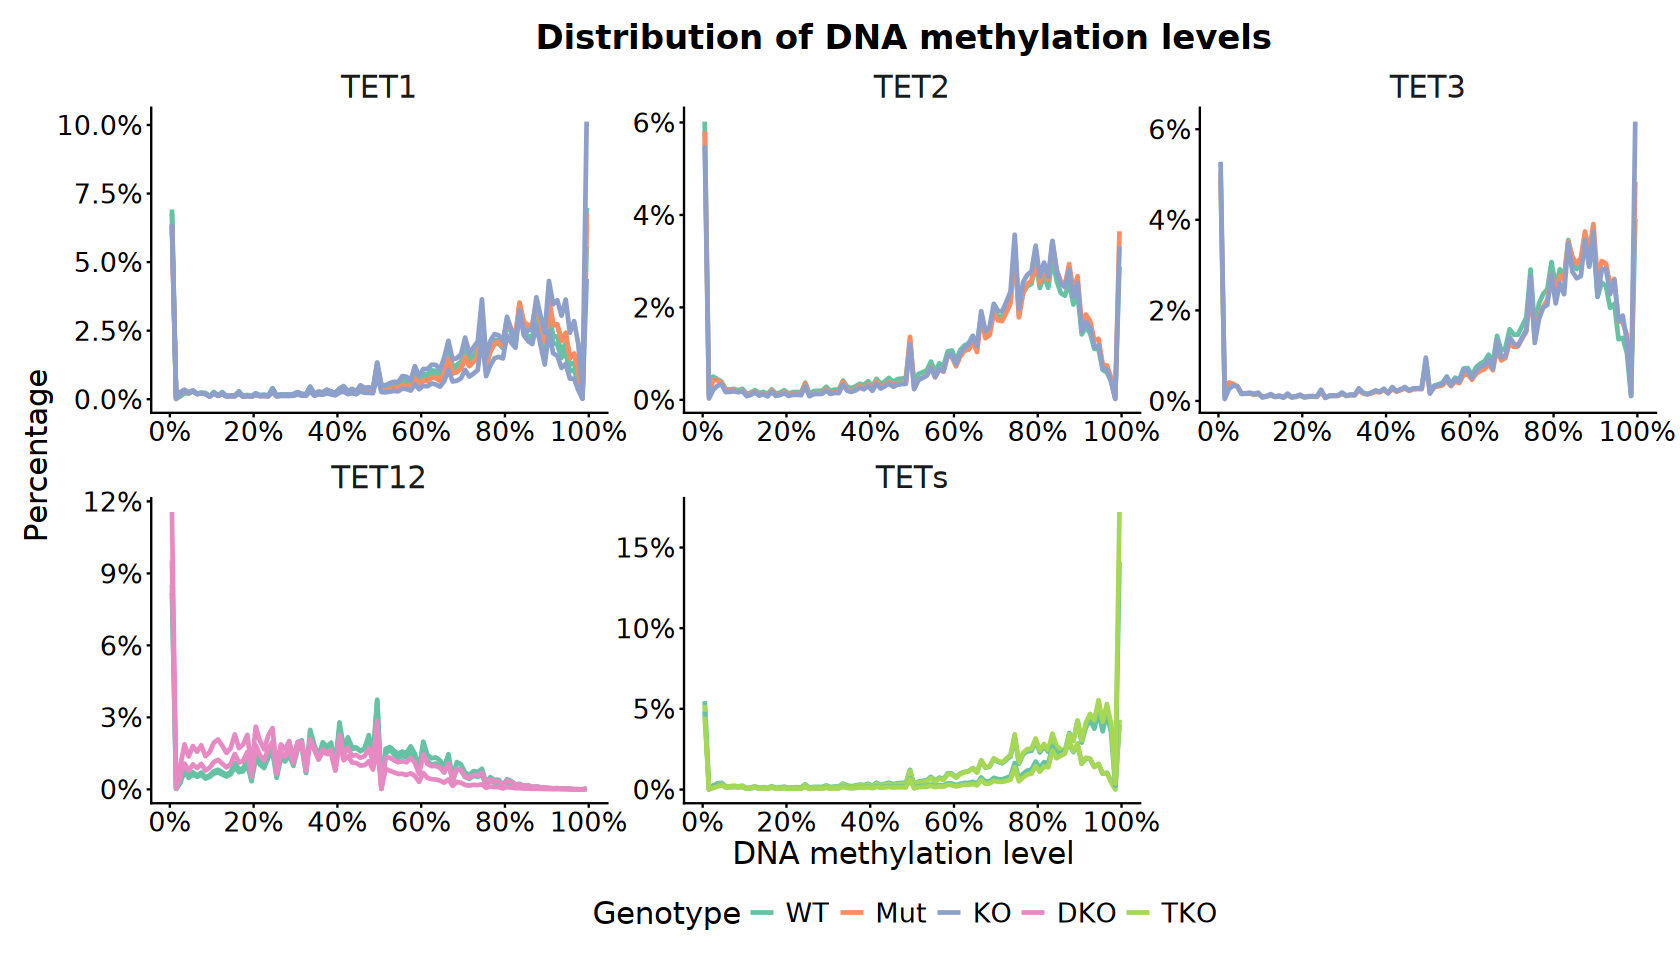

In [20]:
options(repr.plot.width = 14, repr.plot.height = 8)

ggplot(plot_df, aes(x = bin_center, y = prop)) +
    geom_line(aes(color = Genotype, group = sample), linewidth = 1) +
    facet_wrap(~ Gene, nrow = 2, ncol = 3, scales = "free") +
    scale_x_continuous(
        breaks = seq(0, 100, 20), labels = scales::label_percent(scale = 1)) +
    scale_y_continuous(labels = scales::label_percent()) +
    scale_color_brewer(palette = "Set2") +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level", y = "Percentage") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 4. Global Methylation

## 1). Genomic Signal Plot

In [21]:
chr_idx <- "chr2"
chrom_sizes <- seqlengths(genome)[chr_idx]
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6,
    cut.last.tile.in.chrom = TRUE)
names(bins) <- floor((start(bins) + end(bins)) / 2)

In [22]:
bin_stats_list <- lapply(names(signals_list), function(idx) {
    gr <- signals_list[[idx]]
    gr <- gr[seqnames(gr) == chr_idx]

    hits <- findOverlaps(gr, bins, ignore.strand = TRUE)
    if (length(hits) == 0) return(NULL)

    df <- data.table::data.table(
        bin_idx = subjectHits(hits),
        score = gr$score[queryHits(hits)]
    )

    bin_stats <- df[, list(score = mean(score, na.rm = TRUE)), by = bin_idx]

    result <- bins[bin_stats$bin_idx]
    result$score <- bin_stats$score
    result$sample <- idx
    names(result) <- NULL

    return(result)
})

In [23]:
plot_df <- do.call(c, bin_stats_list) |>
    as.data.frame() |>
    mutate(position = (start + end) / 2) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = sample_index))

head(plot_df)

,seqnames,start,end,width,strand,score,sample,position,Cell,Gene,Genotype,Replicate,Group
,<fct>,<int>,<int>,<int>,<fct>,<dbl>,<fct>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>
1,chr2,3000001,4000000,1000000,*,69.87065,mESC_TET1_WT_rep1,3500000,mESC,TET1,WT,rep1,TET1_WT
2,chr2,4000001,5000000,1000000,*,72.43594,mESC_TET1_WT_rep1,4500000,mESC,TET1,WT,rep1,TET1_WT
3,chr2,5000001,6000000,1000000,*,70.97923,mESC_TET1_WT_rep1,5500000,mESC,TET1,WT,rep1,TET1_WT
4,chr2,6000001,7000000,1000000,*,72.23678,mESC_TET1_WT_rep1,6500000,mESC,TET1,WT,rep1,TET1_WT
5,chr2,7000001,8000000,1000000,*,77.71045,mESC_TET1_WT_rep1,7500000,mESC,TET1,WT,rep1,TET1_WT
6,chr2,8000001,9000000,1000000,*,75.36980,mESC_TET1_WT_rep1,8500000,mESC,TET1,WT,rep1,TET1_WT


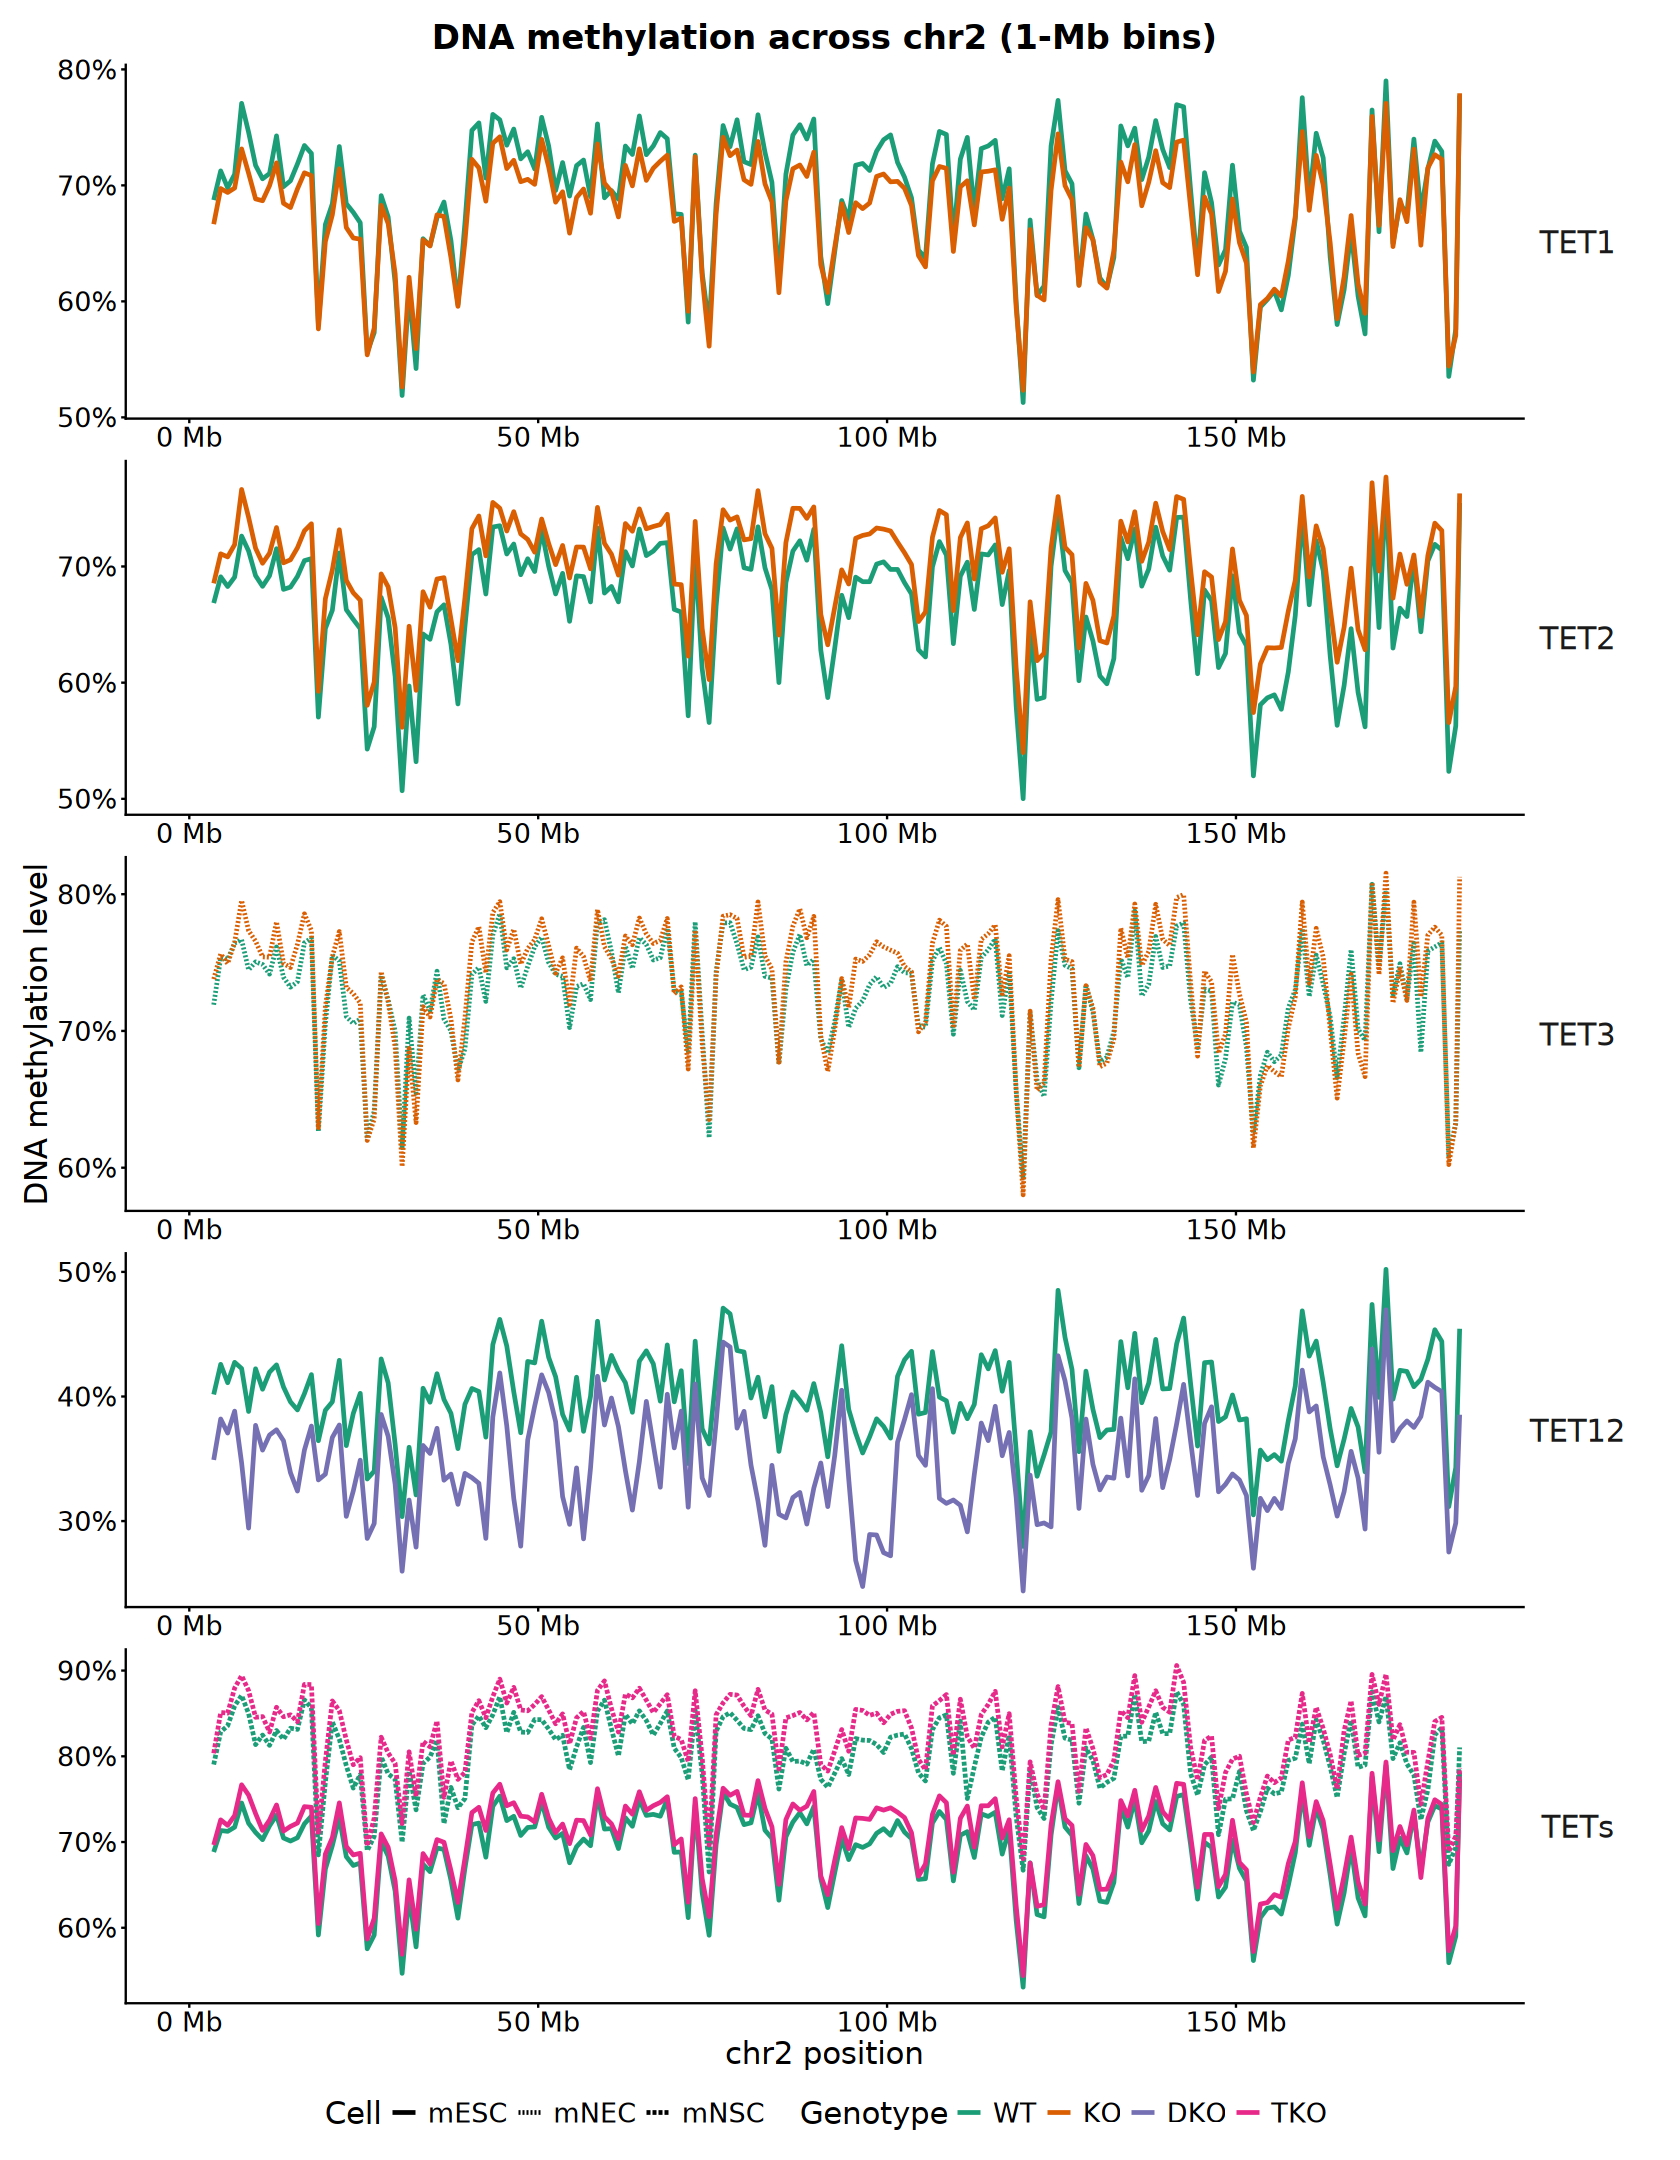

In [24]:
options(repr.plot.width = 14, repr.plot.height = 18)

filter(plot_df, sample %in% c(
        "mESC_TET1_WT_rep2", "mESC_TET1_KO_rep2", 
        "mESC_TET2_WT_repN", "mESC_TET2_KO_repN", 
        "mNEC_TET3_WT_repN", "mNEC_TET3_KO_repN", 
        "mESC_TET12_WT_rep2", "mESC_TET12_DKO_rep2", 
        "mESC_TETs_WT_repN", "mESC_TETs_TKO_repN", 
        "mNSC_TETs_WT_repN", "mNSC_TETs_TKO_repN")) |>
ggplot(aes(x = position, y = score, group = sample)) +
    geom_line(aes(color = Genotype, linetype = Cell), linewidth = 1) +
    facet_wrap(~ Gene, nrow = 6, scales = "free", strip.position = "right") +
    scale_x_continuous(
        limits = c(1, chrom_sizes), breaks = scales::breaks_width(5e7),
        labels = function(x) {paste0(x / 1e6, " Mb")}) +
    scale_y_continuous(
        breaks = seq(0, 100, 10), labels = scales::label_percent(scale = 1)) +
    scale_color_brewer(palette = "Dark2") +
    labs(
        title = paste0("DNA methylation across ", chr_idx, " (1-Mb bins)"),
        x = paste0(chr_idx, " position"), y = "DNA methylation level") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 2, 1, 1), "line"), 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        strip.text.y.right = element_text(angle = 0), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). Metagene Profile

In [25]:
gtf <- import(gtf_file)

GENES <- subset(
    gtf, type == "gene" & gene_type == "protein_coding",
    select = c("gene_id", "gene_name")
)

PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

In [26]:
CGI <- read.table(
    "~/reference/Mus_musculus/mm10/ucsc/cpgIslandExt.txt",
    header = FALSE, sep = "\t", col.names = c(
        "bin", "chr", "start", "end", "names", "length",
        "cpgNum", "gcNum", "perCpg", "perGc", "obsExp")) |>
    dplyr::filter(length > 300) |>
    GRanges() |>
    keepStandardChromosomes(pruning.mode = "coarse")

In [27]:
PROMOTERS$CGI_status <- ifelse(
    overlapsAny(PROMOTERS, CGI), "CGI", "non_CGI") |> 
    factor(levels = c("CGI", "non_CGI"))
table(PROMOTERS$CGI_status)

CGI$Promoter_status <- ifelse(
    overlapsAny(CGI, PROMOTERS), "Promoter", "non_Promoter") |> 
    factor(levels = c("Promoter", "non_Promoter"))
table(CGI$Promoter_status)


    CGI non_CGI 
  10341   11508 


    Promoter non_Promoter 
        9305         3603 

### a). Genes

In [28]:
signals_list_subset <- signals_list[c(
    "mESC_TET1_WT_rep1", "mESC_TET1_KO_rep1", 
    "mESC_TET2_WT_repN", "mESC_TET2_KO_repN", 
    "mNEC_TET3_WT_repN", "mNEC_TET3_KO_repN", 
    "mESC_TET12_WT_rep1", "mESC_TET12_DKO_rep1", 
    "mESC_TETs_WT_repN", "mESC_TETs_TKO_repN")]

In [29]:
# ~ 7 minutes
gene_mat_List <- lapply(
    signals_list_subset, normalizeToMatrix, GENES, value_column = "score", 
    extend = 2000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.4, background = NA, smooth = FALSE)

In [30]:
position_index <- c(
    paste0("u", seq_len(40)), 
    paste0("t", seq_len(53)), 
    paste0("d", seq_len(40))
)

plot_df <- gene_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "score") |>
    mutate(pos = factor(pos, levels = position_index)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = sample_index))

head(plot_df)

sample,pos,score,Cell,Gene,Genotype,Replicate,Group
<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>
mESC_TET1_WT_rep1,u1,63.39106,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,u2,63.27246,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,u3,63.43637,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,u4,62.99487,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,u5,62.89499,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,u6,62.35223,mESC,TET1,WT,rep1,TET1_WT


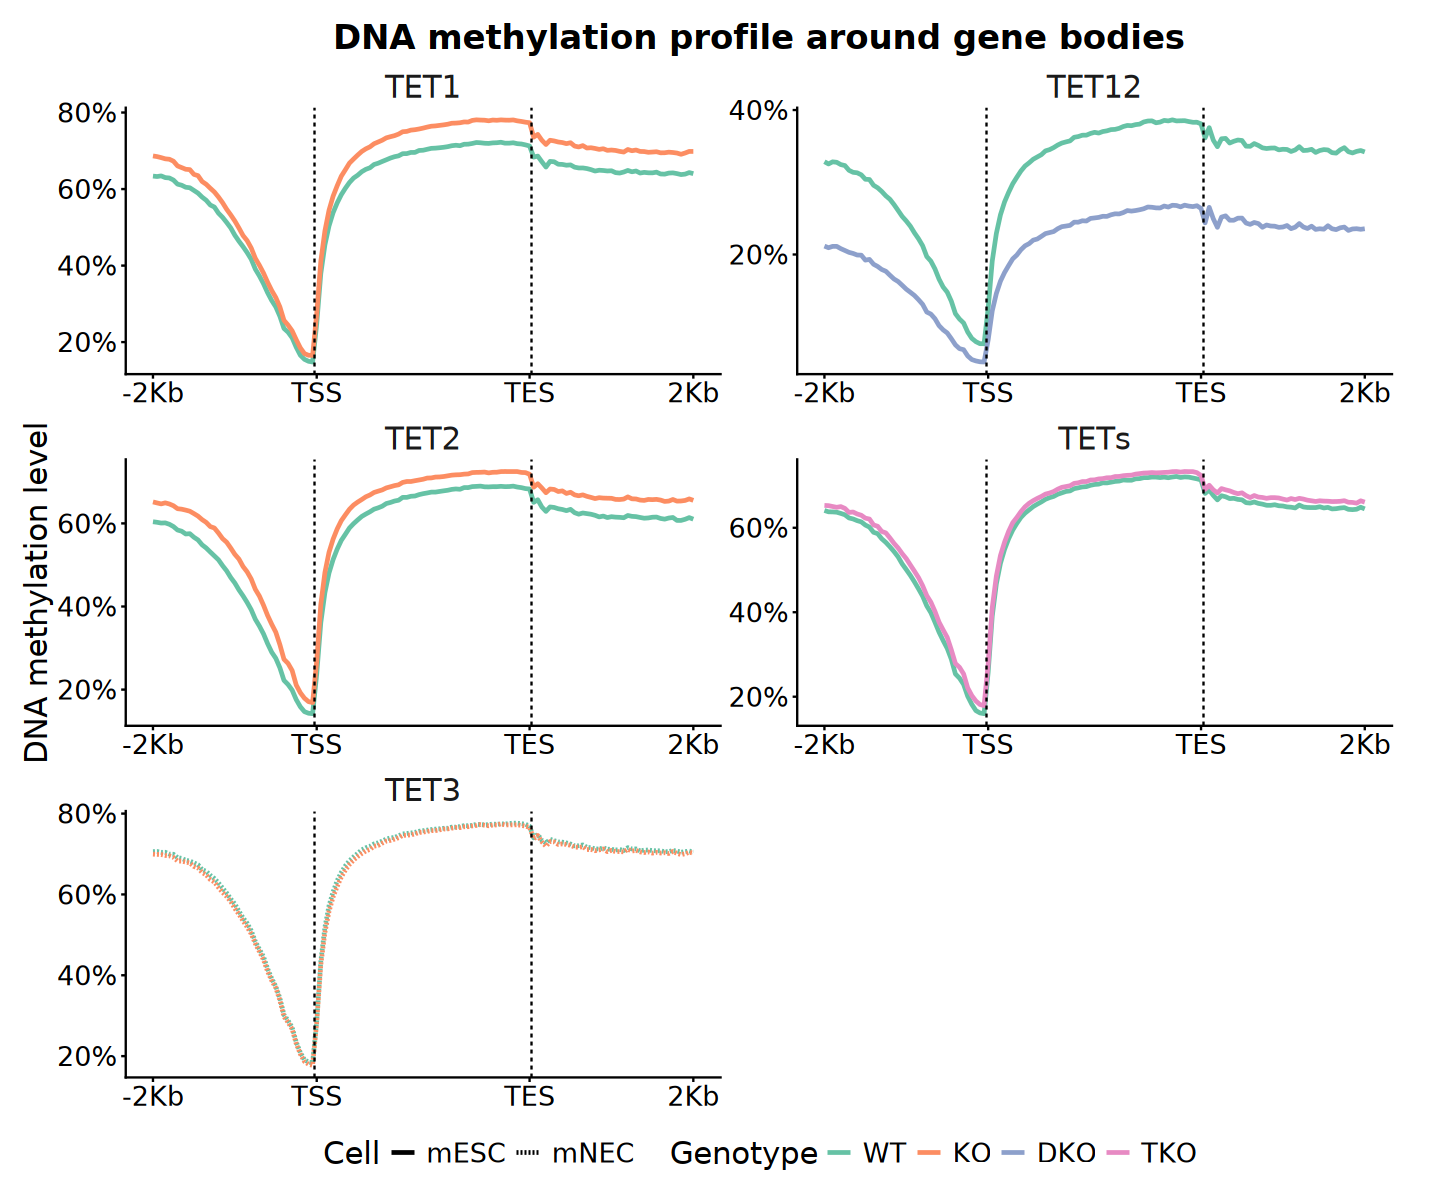

In [31]:
options(repr.plot.width = 12, repr.plot.height = 10)

ggplot(plot_df, aes(x = pos, y = score, group = sample)) +
    geom_line(aes(color = Genotype, linetype = Cell), linewidth = 1) +
    geom_vline(xintercept = 40.5, linetype = 2) +
    geom_vline(xintercept = 93.5, linetype = 2) +
    facet_wrap(~ Gene, nrow = 3, scales = "free", dir = "v") +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), expand = c(0.05, 0.05),
        labels = c("u1" = "-2Kb", "t1" = "TSS", "t53" = "TES", "d40" = "2Kb")) +
    scale_y_continuous(
        breaks = seq(0, 100, 20), labels = scales::label_percent(scale = 1)) +
    scale_color_brewer(palette = "Set2") +
    labs(
        title = "DNA methylation profile around gene bodies", 
        x = NULL, y = "DNA methylation level") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 2, 1, 1), "line"), 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). CGI

In [32]:
# ~ 5 minutes
cgi_mat_List <- lapply(
    signals_list_subset, normalizeToMatrix, CGI, value_column = "score",
    extend = 4000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.3, background = NA, smooth = FALSE)

In [33]:
position_index <- c(
    paste0("u", seq_len(80)), 
    paste0("t", seq_len(69)), 
    paste0("d", seq_len(80))
)

plot_df <- cgi_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "score") |>
    mutate(pos = factor(pos, levels = position_index)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = sample_index))

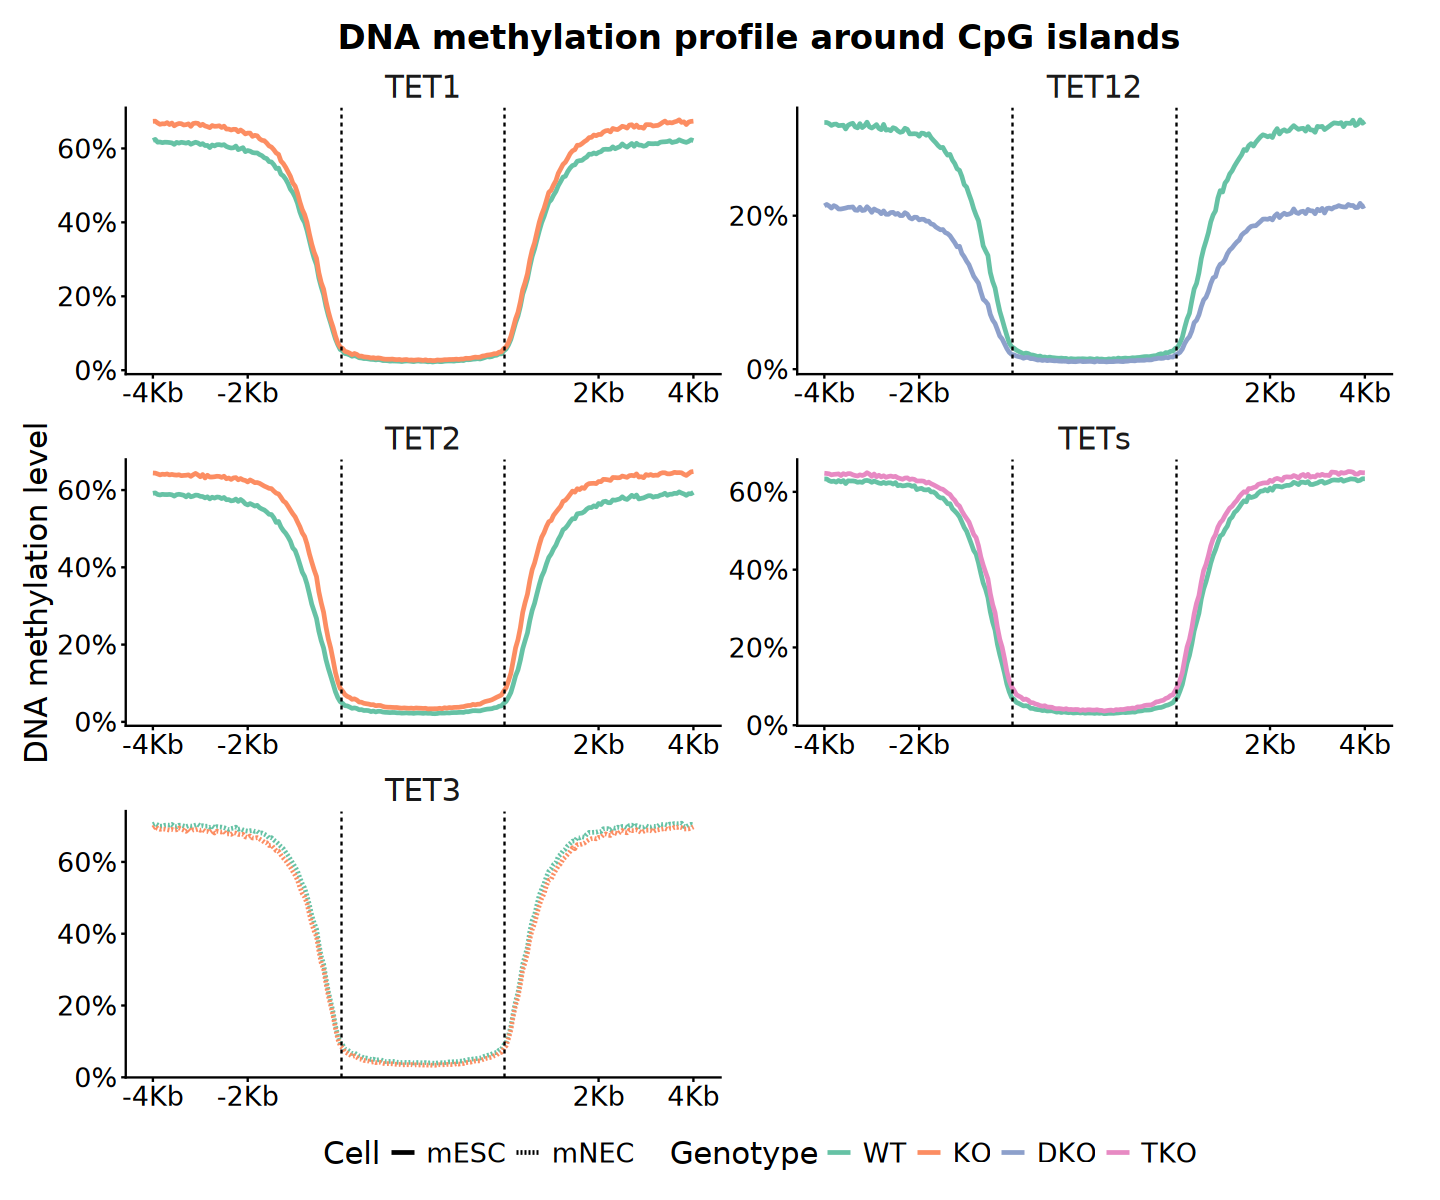

In [34]:
options(repr.plot.width = 12, repr.plot.height = 10)

ggplot(plot_df, aes(x = pos, y = score, group = sample)) +
    geom_line(aes(color = Genotype, linetype = Cell), linewidth = 1) +
    geom_vline(xintercept = 80.5, linetype = 2) +
    geom_vline(xintercept = 149.5, linetype = 2) +
    facet_wrap(~ Gene, nrow = 3, scales = "free", dir = "v") +
    scale_x_discrete(
        breaks = c("u1", "u41", "d40", "d80"), expand = c(0.05, 0.05),
        labels = c(
            "u1" = "-4Kb", "u41" = "-2Kb", "d40" = "2Kb", "d80" = "4Kb")) +
    scale_y_continuous(
        breaks = seq(0, 100, 20), labels = scales::label_percent(scale = 1)) +
    scale_color_brewer(palette = "Set2") +
    labs(
        title = "DNA methylation profile around CpG islands", 
        x = NULL, y = "DNA methylation level") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 2, 1, 1), "line"), 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 3). DNAm Distribution

In [35]:
gene <- genes(txdb)
promoter <- promoters(gene, upstream = 2000, downstream = 500)
downstream <- flank(gene, width = 2000, start = FALSE)

exon <- exonsBy(txdb, by = "gene")
intron <- intronsByTranscript(txdb)

utr5 <- fiveUTRsByTranscript(txdb)
cds <- cdsBy(txdb, by = "gene")
utr3 <- threeUTRsByTranscript(txdb)

gap <- c(gene, promoter, downstream) |> unstrand() |> gaps()
intergenic <- gap[strand(gap) == "*"]

  66 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [36]:
# CGI shore = ±2kb around CGI excluding CGI
# CGI shelf = 2–4kb around CGI excluding 0–2kb, CGI
cgi_2kb <- resize(CGI, width = width(CGI) + 4000, fix = "center")
cgi_shore <- setdiff(cgi_2kb, CGI)
cgi_4kb <- resize(CGI, width = width(CGI) + 8000, fix = "center")
cgi_shelf <- setdiff(cgi_4kb, cgi_2kb)

In [37]:
region_list <- list(
    CGI = CGI, CGI_Shore = cgi_shore, CGI_Shelf = cgi_shelf,
    Promoter = promoter, Exon = unlist(exon), Intron = unlist(intron),
    FiveUTR = unlist(utr5), CDS = unlist(cds), ThreeUTR = unlist(utr3),
    Downstream = downstream, Intergenic = intergenic
)

In [38]:
get_profile_data <- function(
    gr, region, region_id, bin = 50, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    hits <- findOverlaps(gr, region, ignore.strand = TRUE)

    if(length(hits) == 0) return(NULL)

    gr_sub <- gr[queryHits(hits)]
    region_sub <- region[subjectHits(hits)]

    rel_pos <- (start(gr_sub) - start(region_sub)) / width(region_sub)
    is_minus <- as.character(strand(region_sub)) == "-"
    rel_pos[is_minus] <- 1 - rel_pos[is_minus]

    bin_idx <- ceiling(rel_pos * bin)
    bin_idx[bin_idx == 0] <- 1
    bin_idx[bin_idx > bin] <- bin

    if (method == "mean") {
        vals <- mcols(gr_sub)[[meth_col]]
        mean <- mean(vals, na.rm = TRUE)
        df <- tibble(bin = bin_idx, meth = vals) |> 
            group_by(bin) |>
            summarise(mean = mean(meth, na.rm = TRUE), .groups = "drop") |>
            mutate(region = region_id)
    } else if (method == "ratio") {
        numCs <- mcols(gr_sub)[[numCs_col]]
        numTs <- mcols(gr_sub)[[numTs_col]]
        df <- tibble(bin = bin_idx, numCs = numCs, numTs = numTs) |>
            group_by(bin) |>
            summarise(
                mean = sum(numCs) / sum(numCs + numTs) * 100, 
                .groups = "drop") |>
            mutate(region = region_id)
    }

    return(df)
}

In [39]:
region_index <- c(
    "Promoter", "FiveUTR", "Exon", "Intron", "ThreeUTR", 
    "Downstream", "Intergenic")

profiles_list <- list()

for (sample_idx in names(signals_list_subset)) {
    meth <- signals_list_subset[[sample_idx]]
    result <- lapply(region_index, function(idx) {
        region <- region_list[[idx]]
        df <- get_profile_data(
            meth, region, idx, bin = 50, method = "mean", meth_col = "score")
        return(df)
    })

    profiles_list[[sample_idx]] <- bind_rows(result) |>
        mutate(
            sample = sample_idx, 
            region = factor(region, levels = region_index))
}

In [40]:
plot_df <- bind_rows(profiles_list) |>
    mutate(region_idx = as.numeric(region) - 1) |>
    mutate(global_idx = (region_idx * 50) + bin) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = sample_index))

head(plot_df)

bin,mean,region,sample,region_idx,global_idx,Cell,Gene,Genotype,Replicate,Group
<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>
1,57.87706,Promoter,mESC_TET1_WT_rep1,0,1,mESC,TET1,WT,rep1,TET1_WT
2,57.74677,Promoter,mESC_TET1_WT_rep1,0,2,mESC,TET1,WT,rep1,TET1_WT
3,57.75759,Promoter,mESC_TET1_WT_rep1,0,3,mESC,TET1,WT,rep1,TET1_WT
4,57.35401,Promoter,mESC_TET1_WT_rep1,0,4,mESC,TET1,WT,rep1,TET1_WT
5,57.18338,Promoter,mESC_TET1_WT_rep1,0,5,mESC,TET1,WT,rep1,TET1_WT
6,56.16057,Promoter,mESC_TET1_WT_rep1,0,6,mESC,TET1,WT,rep1,TET1_WT


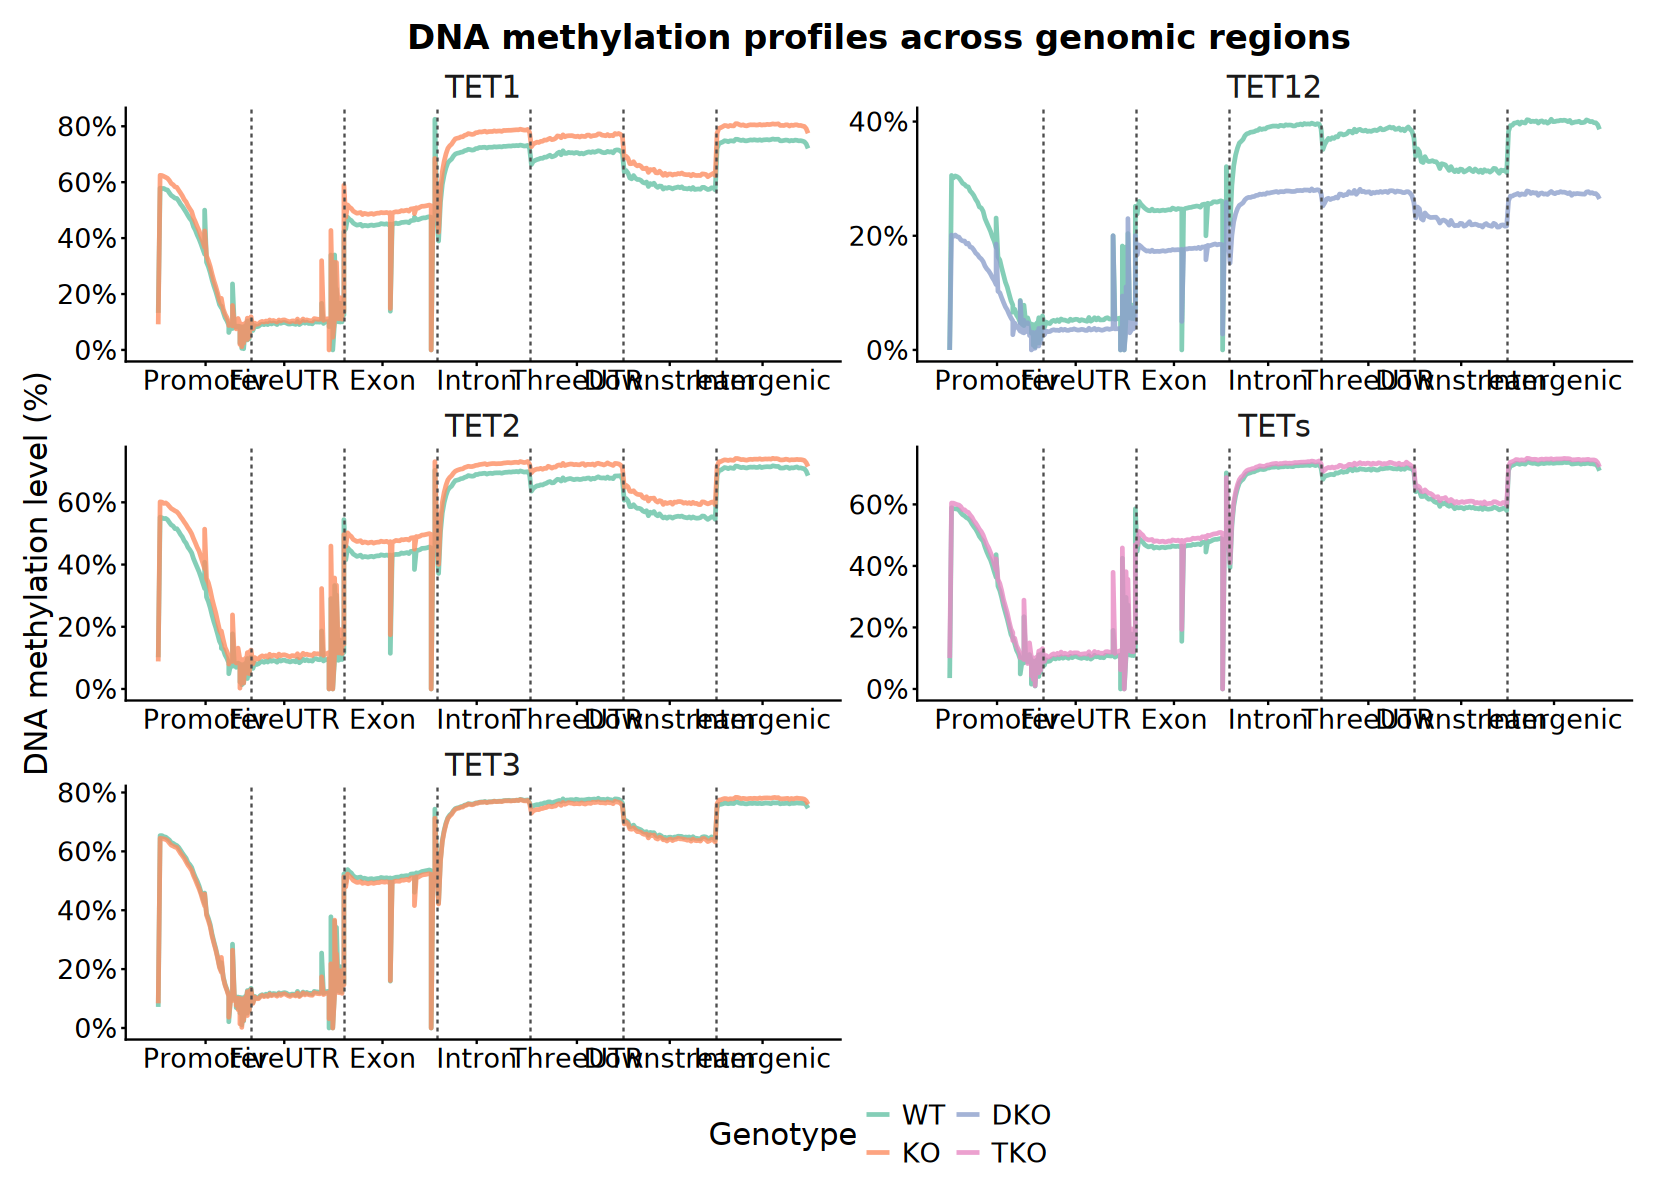

In [41]:
options(repr.plot.width = 14, repr.plot.height = 10)

x_labels_pos <- plot_df |> group_by(region) |>
    summarise(center_idx = mean(global_idx), .groups = "drop")
vlines_pos <- seq(50 + 0.5, max(plot_df$global_idx) - 50 + 0.5, by = 50)

ggplot(plot_df, aes(x = global_idx, y = mean, group = sample)) +
    geom_line(aes(color = Genotype), linewidth = 1, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = vlines_pos, color = "grey30", linetype = "dashed") +
    facet_wrap(~ Gene, nrow = 3, scales = "free", dir = "v") +
    scale_x_continuous(
        breaks = x_labels_pos$center_idx, labels = x_labels_pos$region) +
    scale_y_continuous(
        breaks = seq(0, 100, 20), labels = scales::label_percent(scale = 1)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profiles across genomic regions",
        x = NULL, y = "DNA methylation level (%)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 2, 1, 1), "line"), 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [42]:
get_region_data <- function(
    gr, region_list, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    map_dfr(names(region_list), function(idx) {
        hits <- findOverlaps(gr, region_list[[idx]], ignore.strand = TRUE)
        sub_gr <- gr[queryHits(hits)]

        if (method == "mean") {
            vals <- mcols(sub_gr)[[meth_col]]
            mean <- mean(vals, na.rm = TRUE)
        } else if (method == "ratio") {
            numCs <- mcols(sub_gr)[[numCs_col]]
            numTs <- mcols(sub_gr)[[numTs_col]]

            sumCs <- sum(numCs, na.rm = TRUE)
            sumTs <- sum(numTs, na.rm = TRUE)
            mean <- sumCs / (sumCs + sumTs) * 100
        }
        tibble(region = idx, numCpG = length(sub_gr), mean = mean)
    })
}

In [43]:
meth_df <- imap_dfr(signals_list_subset, function(gr, sample_id) {
    get_region_data(gr, region_list, method = "mean", meth_col = "score")
}, .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = sample_index))

head(meth_df)

sample,region,numCpG,mean,Cell,Gene,Genotype,Replicate,Group
<fct>,<chr>,<int>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>
mESC_TET1_WT_rep1,CGI,994278,2.443852,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,CGI_Shore,780813,33.361015,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,CGI_Shelf,490293,64.478234,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,Promoter,1497075,20.347743,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,Exon,3179898,45.648947,mESC,TET1,WT,rep1,TET1_WT
mESC_TET1_WT_rep1,Intron,33242707,69.434389,mESC,TET1,WT,rep1,TET1_WT


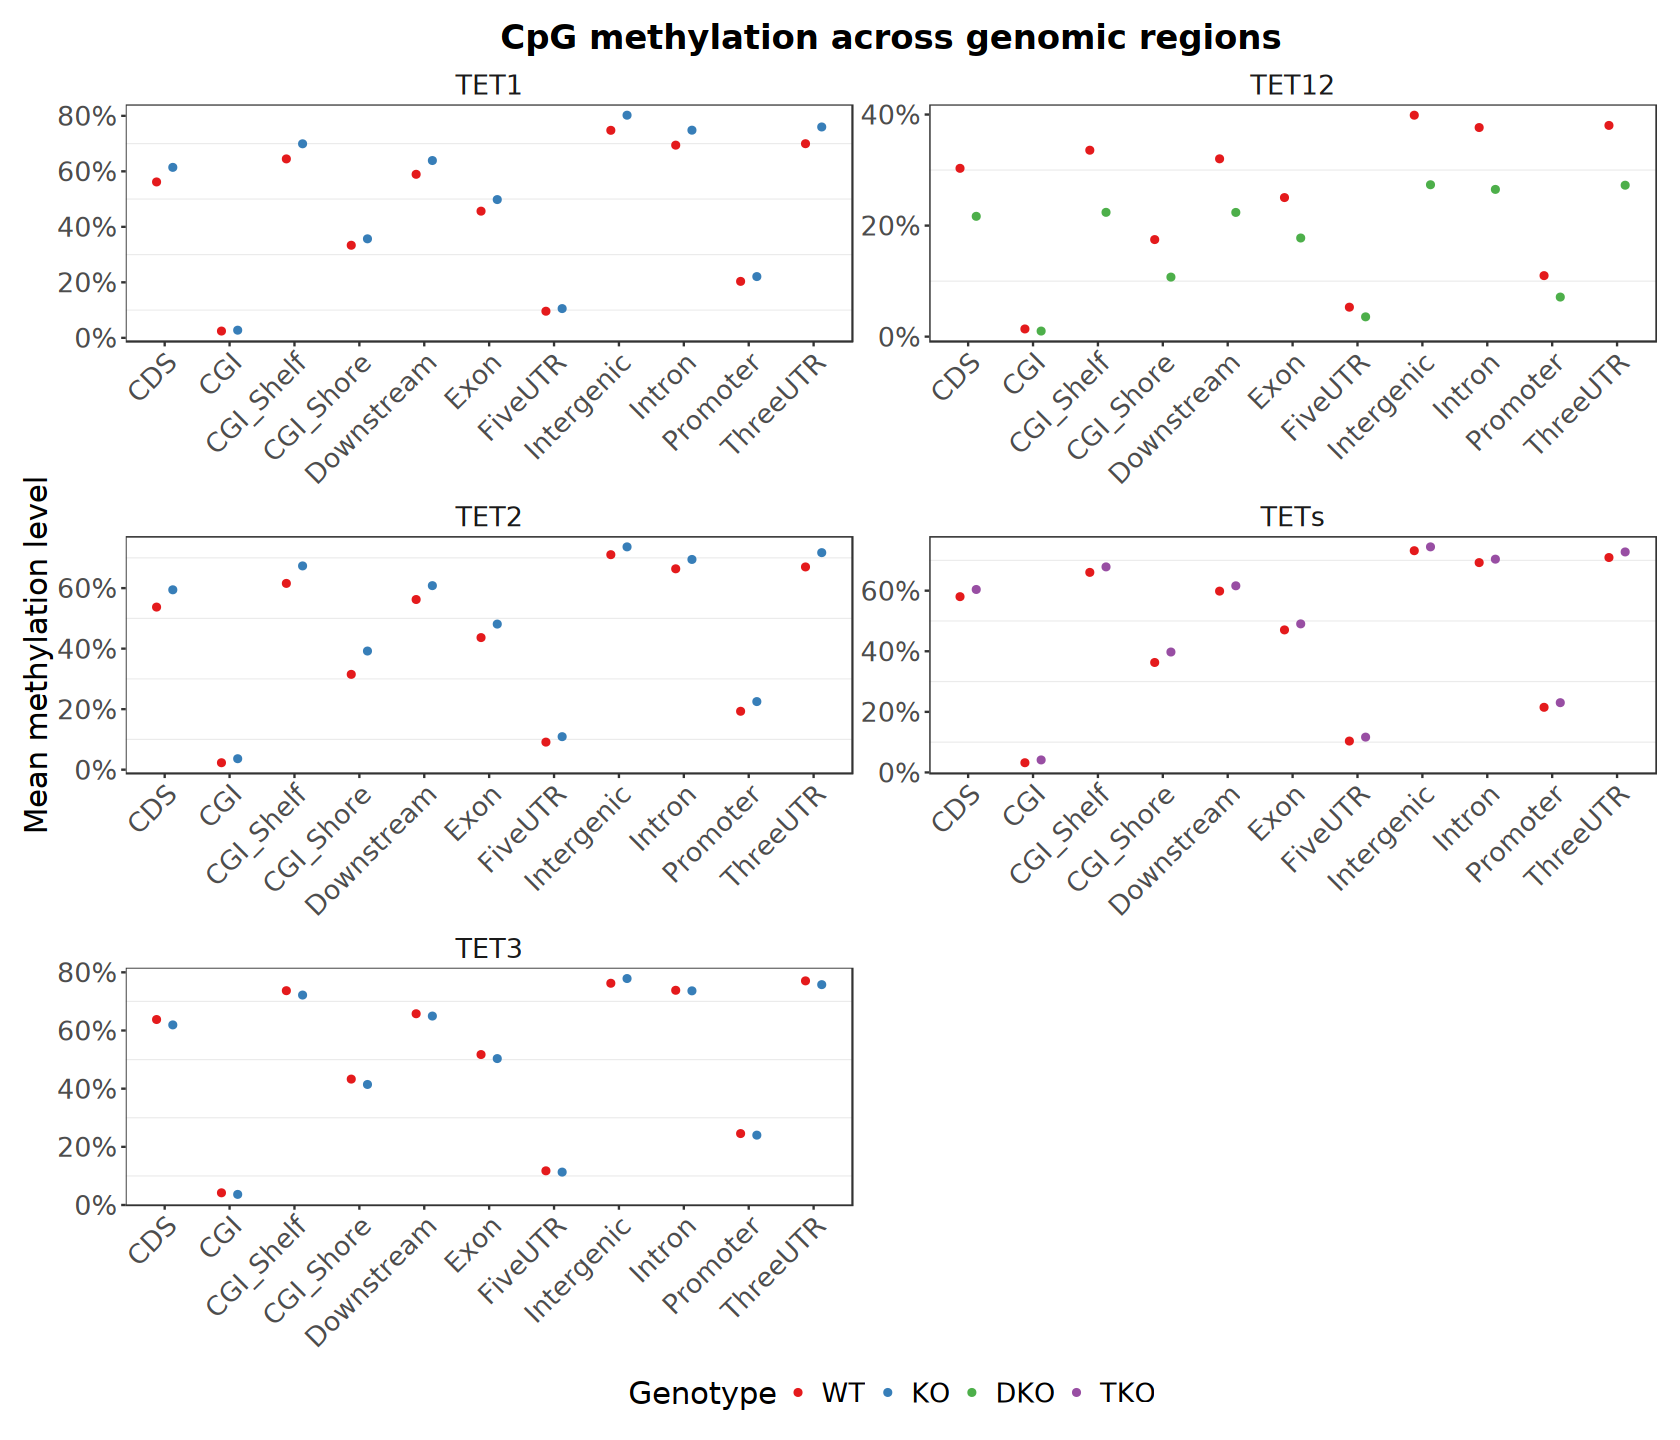

In [44]:
options(repr.plot.width = 14, repr.plot.height = 12)

ggplot(meth_df, aes(x = region, y = mean)) +
    geom_point(aes(color = Genotype), position = position_dodge(width = 0.5)) +
    facet_wrap(~ Gene, nrow = 3, scales = "free", dir = "v") +
    scale_y_continuous(
        breaks = seq(0, 100, 20), labels = scales::label_percent(scale = 1)) +
    # ggthemes::scale_color_tableau(palette = "Tableau 20") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        strip.text = element_text(size = 16),
        strip.background = element_blank(), 
        strip.placement = "outside",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

# * Reference